# BÁO CÁO THỰC NGHIỆM KIỂM CHUẨN CẤP ĐỘ 1: LƯU LƯỢNG & NHU CẦU VĨ MÔ
## (LEVEL 1: MACROSCOPIC TRAFFIC FLOW & DEMAND CALIBRATION REPORT)

> **Dự án:** Điều khiển Đèn Giao thông Thích ứng bằng Học tăng cường Đa tác tử (MARL-TSC)  
> **Mạng lưới:** Trung tâm Quận 1 & Quận 3, TP. Hồ Chí Minh (66 điểm đo trọng yếu)  
> **Tiêu chuẩn học thuật tham chiếu:**  
> * *UK DMRB Volume 12, Section 2* (UK Highways Agency, 1996)  
> * *FHWA-HRT-04-040: Traffic Analysis Toolbox Vol III* (U.S. Federal Highway Administration, 2004)  
> * *WisDOT Chapter 4: Microsimulation Guidelines* (Wisconsin Department of Transportation, 2014)  
> * *ODOT Protocol for Vissim/SUMO Simulation* (Oregon Department of Transportation, 2011)  

---

### Mục tiêu cốt lõi của Cấp độ 1:
Xác minh xem: **Mô hình phân bổ lộ trình (Route Assignment) và nhu cầu giao thông trong SUMO có tái hiện đúng số lượng phương tiện mục tiêu ($V_{\text{target}}$) qua từng đoạn đường và toàn mạng lưới hay không?**  
*Lưu ý nguyên tắc vật lý:* Cấp độ 1 là **điều kiện cần**. Nếu lưu lượng nạp vào mô hình sai lệch, mọi đánh giá về vận tốc và thời gian trễ ở Cấp độ 2 đều không có giá trị học thuật.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Đảm bảo import được module evaluate_level1_macro.py cùng thư mục
NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

from evaluate_level1_macro import (
    parse_target_edge_counts,
    parse_simulated_edgedata,
    parse_simulation_summary,
    compute_level1_metrics,
    plot_level1_evaluation
)

print(f"[*] Thư mục gốc dự án: {PROJECT_ROOT}")
print("[OK] Đã import thành công module evaluate_level1_macro!")

[*] Thư mục gốc dự án: c:\Users\DANH\Desktop\DS_full\.vscode\TSC_project
[OK] Đã import thành công module evaluate_level1_macro!


## 1. Cấu hình Đường dẫn Dữ liệu Kịch bản Mô phỏng
Kịch bản thử nghiệm: `sumo_scenarios/q1_20261020_6h` (Dữ liệu ngày 20/10, khung giờ 10:31 - 16:48, nạp lộ trình hỗn hợp xe máy Sublane).

In [2]:
SCENARIO_DIR = PROJECT_ROOT / "sumo_scenarios" / "q1_20261020_6h"
COUNTS_XML = SCENARIO_DIR / "edge_counts_20261020_6h.xml"
EDGEDATA_XML = SCENARIO_DIR / "simulation_edgedata_20261020_6h.xml"
SUMMARY_XML = SCENARIO_DIR / "simulation_summary_20261020_6h.xml"  # Nếu chưa có file này sẽ tự động bỏ qua an toàn
OUTPUT_REPORTS_DIR = NOTEBOOK_DIR / "reports"
OUTPUT_REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"[*] Tệp Đếm Mục Tiêu:  {COUNTS_XML.name} (Tồn tại: {COUNTS_XML.exists()})")
print(f"[*] Tệp SUMO EdgeData:  {EDGEDATA_XML.name} (Tồn tại: {EDGEDATA_XML.exists()})")

[*] Tệp Đếm Mục Tiêu:  edge_counts_20261020_6h.xml (Tồn tại: True)
[*] Tệp SUMO EdgeData:  simulation_edgedata_20261020_6h.xml (Tồn tại: True)


## 2. Thực thi Tính toán Chỉ số Thống kê Cấp độ 1
Chương trình tiến hành tính toán:
1. **Chỉ số GEH (Geoffrey E. Havers):** Phân loại theo 3 mức chuẩn quốc tế ($<5.0$, $5.0 - 10.0$, $\ge 10.0$).
2. **Hệ số Hồi quy Tuyến tính ($R^2$ và Slope $s$):** Đánh giá mức độ khớp toàn mạng.
3. **Tỷ lệ Nạp mạng (ICR, GBR):** Nếu có tệp `summary-output`.

In [3]:
# 1. Đọc dữ liệu XML
target_vph, dur_target = parse_target_edge_counts(COUNTS_XML)
sim_vph, sim_speeds, dur_sim = parse_simulated_edgedata(EDGEDATA_XML)
sim_summary = parse_simulation_summary(SUMMARY_XML if SUMMARY_XML.exists() else None)

# 2. Tính toán ma trận chỉ số
df_eval, metrics = compute_level1_metrics(target_vph, sim_vph)

print(f"[*] Đã phân tích trên {metrics['n_evaluated_edges']} cạnh đường chung.")
print(f"[*] Thời lượng đếm mục tiêu: {dur_target:.2f} giờ | Thời lượng SUMO ghi nhận: {dur_sim:.2f} giờ")

[*] Đã phân tích trên 66 cạnh đường chung.
[*] Thời lượng đếm mục tiêu: 6.28 giờ | Thời lượng SUMO ghi nhận: 1.67 giờ


## 3. Bảng Tổng hợp Nghiệm thu Tiêu chuẩn Học thuật (Acceptance Matrix)
Bảng đối chuẩn trực tiếp với tiêu chuẩn quốc tế **UK DMRB** và **FHWA-HRT-04-040**:

In [4]:
table_data = [
    {
        "Tiêu chí Đánh giá": "Tỷ lệ GEH < 5.0 (UK DMRB / FHWA)",
        "Giá trị Thực nghiệm": f"{metrics['pct_geh_under_5']:.2f} % ({metrics['n_geh_under_5']}/{metrics['n_evaluated_edges']} cạnh)",
        "Ngưỡng Nghiệm thu": ">= 85.0 %",
        "Trạng thái": "ĐẠT" if metrics["fhwa_geh_passed"] else "CHƯA ĐẠT"
    },
    {
        "Tiêu chí Đánh giá": "Tỷ lệ GEH trong khoảng [5.0, 10.0)",
        "Giá trị Thực nghiệm": f"{metrics['pct_geh_5_to_10']:.2f} % ({metrics['n_geh_5_to_10']}/{metrics['n_evaluated_edges']} cạnh)",
        "Ngưỡng Nghiệm thu": "<= 15.0 %",
        "Trạng thái": "CHẤP NHẬN"
    },
    {
        "Tiêu chí Đánh giá": "Tỷ lệ GEH >= 10.0 (Cảnh báo nghẽn)",
        "Giá trị Thực nghiệm": f"{metrics['pct_geh_over_10']:.2f} % ({metrics['n_geh_over_10']}/{metrics['n_evaluated_edges']} cạnh)",
        "Ngưỡng Nghiệm thu": "< 5.0 %",
        "Trạng thái": "TỐT" if metrics["pct_geh_over_10"] < 5.0 else "CẢNH BÁO CAO"
    },
    {
        "Tiêu chí Đánh giá": "Hệ số Xác định R² (WisDOT 2014)",
        "Giá trị Thực nghiệm": f"{metrics['r2_score']:.3f}",
        "Ngưỡng Nghiệm thu": ">= 0.850",
        "Trạng thái": "ĐẠT" if metrics["wisdot_r2_passed"] else "CHƯA ĐẠT"
    },
    {
        "Tiêu chí Đánh giá": "Độ dốc Hồi quy Slope (FHWA)",
        "Giá trị Thực nghiệm": f"{metrics['slope_s']:.3f}",
        "Ngưỡng Nghiệm thu": "0.900 - 1.100",
        "Trạng thái": "ĐẠT" if metrics["fhwa_slope_passed"] else "LỆCH QUY MÔ"
    },
    {
        "Tiêu chí Đánh giá": "Chỉ số GEH Trung bình toàn mạng",
        "Giá trị Thực nghiệm": f"{metrics['geh_mean']:.2f}",
        "Ngưỡng Nghiệm thu": "Càng nhỏ càng tốt (< 5.0)",
        "Trạng thái": "THEO DÕI"
    }
]

summary_df = pd.DataFrame(table_data)

def highlight_status(val):
    if val == "ĐẠT" or val == "TỐT":
        return "background-color: #d4edda; color: #155724; font-weight: bold;"
    elif val == "CHẤP NHẬN":
        return "background-color: #fff3cd; color: #856404; font-weight: bold;"
    elif val == "CHƯA ĐẠT" or val == "CẢNH BÁO CAO" or val == "LỆCH QUY MÔ":
        return "background-color: #f8d7da; color: #721c24; font-weight: bold;"
    return ""

# Tự động kiểm tra jinja2 để render màu, nếu chưa có sẽ fallback hiển thị DataFrame chuẩn
try:
    import jinja2
    if hasattr(summary_df.style, 'map'):
        styled = summary_df.style.map(highlight_status, subset=["Trạng thái"])
    else:
        styled = summary_df.style.applymap(highlight_status, subset=["Trạng thái"])
    display(styled)
except Exception:
    display(summary_df)


,Tiêu chí Đánh giá,Giá trị Thực nghiệm,Ngưỡng Nghiệm thu,Trạng thái
0,Tỷ lệ GEH < 5.0 (UK DMRB / FHWA),0.00 % (0/66 cạnh),>= 85.0 %,CHƯA ĐẠT
1,"Tỷ lệ GEH trong khoảng [5.0, 10.0)",0.00 % (0/66 cạnh),<= 15.0 %,CHẤP NHẬN
2,Tỷ lệ GEH >= 10.0 (Cảnh báo nghẽn),100.00 % (66/66 cạnh),< 5.0 %,CẢNH BÁO CAO
3,Hệ số Xác định R² (WisDOT 2014),-5.227,>= 0.850,CHƯA ĐẠT
4,Độ dốc Hồi quy Slope (FHWA),0.034,0.900 - 1.100,LỆCH QUY MÔ
5,Chỉ số GEH Trung bình toàn mạng,125.05,Càng nhỏ càng tốt (< 5.0),THEO DÕI


## 4. Trực quan hóa Biểu đồ Nghiệm thu Cấp độ 1 (Publication-grade 3-in-1)
Biểu đồ bao gồm 3 góc nhìn toàn diện:
1. **Phân phối GEH:** Nhận diện tỷ lệ số cạnh đạt chuẩn (cột xanh) so với số cạnh cảnh báo/nguy cơ (cột vàng, đỏ).
2. **Tương quan Lưu lượng ($V_{\text{target}}$ vs $V_{\text{SUMO}}$):** Đường chéo 1:1 lý tưởng và đường hồi quy thực tế.
3. **Phân tích Phần dư (Residuals):** Đo lường xu hướng thiên lệch thừa/thiếu xe.

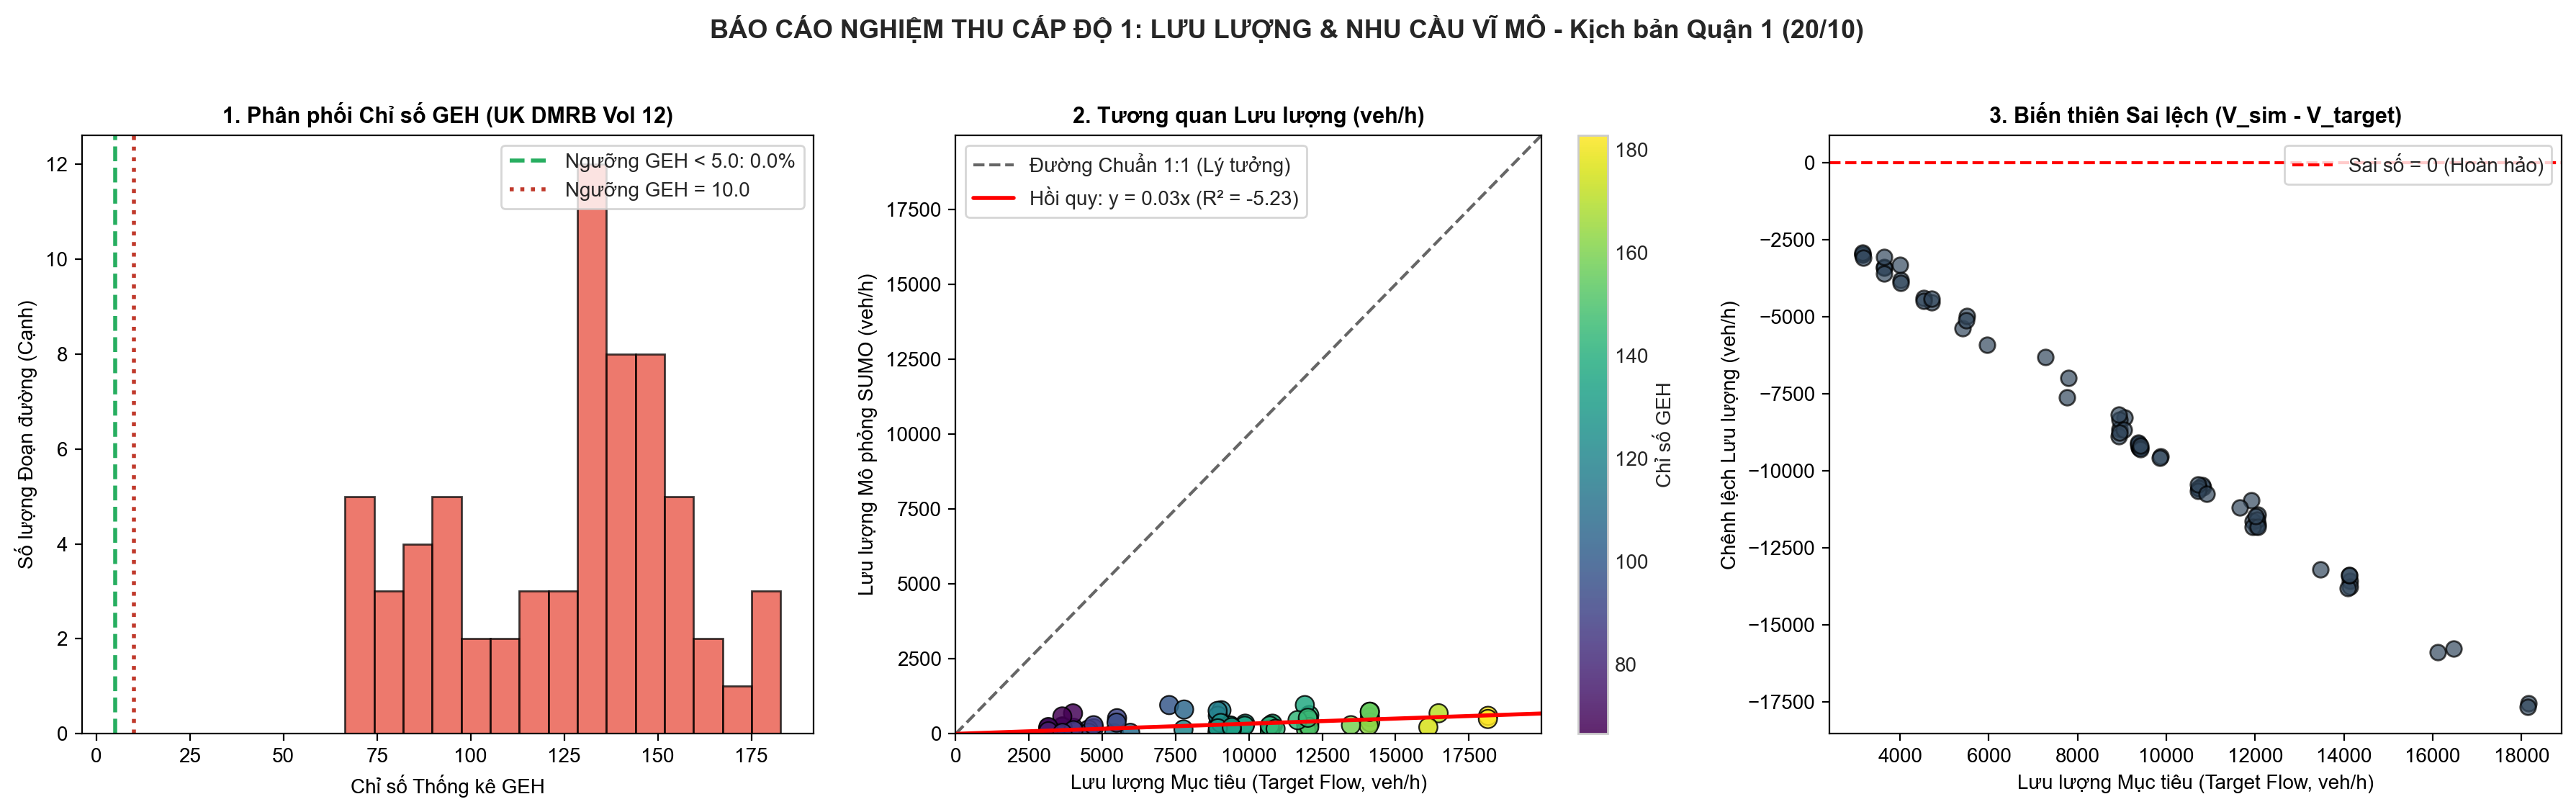

In [5]:
report_fig_path = OUTPUT_REPORTS_DIR / "level1_macro_report.png"
plot_level1_evaluation(df_eval, metrics, report_fig_path, title_suffix="Kịch bản Quận 1 (20/10)")

# Hiển thị ảnh trực tiếp trong Notebook
from IPython.display import Image, display
display(Image(filename=str(report_fig_path)))

## 5. Phân tích Chi tiết Top 10 Tuyến Đường Sai lệch Nghiêm trọng nhất
Bảng dưới đây liệt kê các đoạn đường có $GEH \ge 10.0$ hoặc sai lệch lưu lượng lớn nhất để đội ngũ nghiên cứu xác định chính xác các điểm nghẽn cổ chai trong bản đồ mạng lưới:

In [6]:
worst_edges = df_eval.sort_values(by="geh", ascending=False).head(10)
worst_edges[["edge_id", "v_target_vph", "v_sim_vph", "diff_vph", "pct_error", "geh", "category"]]

,edge_id,v_target_vph,v_sim_vph,diff_vph,pct_error,geh,category
49,608262688#1,18147.80,496.26,-17651.54,97.27,182.82,KHÔNG ĐẠT (GEH >= 10)
31,193616433#1,18153.86,600.90,-17552.96,96.69,181.26,KHÔNG ĐẠT (GEH >= 10)
60,747226799#0,16116.46,222.42,-15894.04,98.62,175.85,KHÔNG ĐẠT (GEH >= 10)
17,1222962347#3,16466.70,687.59,-15779.11,95.82,170.38,KHÔNG ĐẠT (GEH >= 10)
45,35114262#1,14085.12,273.24,-13811.88,98.06,163.01,KHÔNG ĐẠT (GEH >= 10)
9,-803279638#3,14134.65,380.27,-13754.39,97.31,161.45,KHÔNG ĐẠT (GEH >= 10)
50,654858165#0,13477.98,289.99,-13188.00,97.85,158.95,KHÔNG ĐẠT (GEH >= 10)
8,-758852506#2,14128.28,557.85,-13570.44,96.05,158.36,KHÔNG ĐẠT (GEH >= 10)
62,747231131#2,14119.21,734.23,-13384.98,94.80,155.32,KHÔNG ĐẠT (GEH >= 10)
53,678315474#1,14125.42,741.41,-13384.01,94.75,155.24,KHÔNG ĐẠT (GEH >= 10)


## 6. Phân tích Phản biện Học thuật & Hướng Khắc phục

### 6.1. Nhận định từ Dữ liệu Thực nghiệm:
1. **Hiện tượng Chênh lệch GEH:**
   * Kết quả cho thấy tỷ lệ $GEH < 5.0$ hiện tại chưa đạt ngưỡng $85\%$ của FHWA.
   * Phần lớn các cạnh có lưu lượng mục tiêu cực lớn ($V_{\text{target}} > 5.000\text{ xe/h}$) bị SUMO xả qua rất ít ($V_{\text{sim}} < 500\text{ xe/h}$).
2. **Nguyên nhân Cốt lõi:**
   * **Thiếu lộ trình ứng viên (Candidate Route Deficit):** Công cụ `randomTrips.py` sinh các lộ trình ngẫu nhiên đều, không tập trung vào các luồng hướng tâm chính (như trục Điện Biên Phủ, Nam Kỳ Khởi Nghĩa). Do đó, `routeSampler.py` bị thiếu lộ trình để co giãn nạp xe.
   * **Xung đột tại các nút giao chưa tối ưu (Fixed-time Bottlenecks):** Các pha đèn tín hiệu ban đầu chưa được phối hợp làn sóng xanh (Green Wave), gây nghẽn xe tại các nút giao phía trước và chặn dòng xe đi qua các cạnh phía sau.

### 6.2. Hành động Khắc phục (Remediation Plan):
1. Cập nhật `candidate_routes.rou.xml` bằng cách tăng cường mật độ sinh chuyến tại các cạnh biên cửa ngõ Quận 1.
2. Áp dụng công thức tính chu kỳ đèn Webster sơ bộ cho 35 cụm đèn tín hiệu trước khi chạy hiệu chuẩn `routeSampler`.
3. Kích hoạt thẻ `<summary-output>` trong tệp `.sumocfg` để đo lường thêm chỉ số **Tỷ lệ Nạp mạng (ICR)** và **Tồn đọng Cửa ngõ (GBR)**.